# Boolean circuits with fixed weights

Construct a two-unit network that computes exclusive OR on every binary input.

The hidden units compute the positive and negative parts of x minus y. Summing their rectified outputs gives the absolute difference. On binary inputs that equals XOR. This specifies every parameter before any examples are evaluated.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

x y | h1 h2 | XOR
[[0 0 0 0 0]
 [0 1 0 1 1]
 [1 0 1 0 1]
 [1 1 0 0 0]]


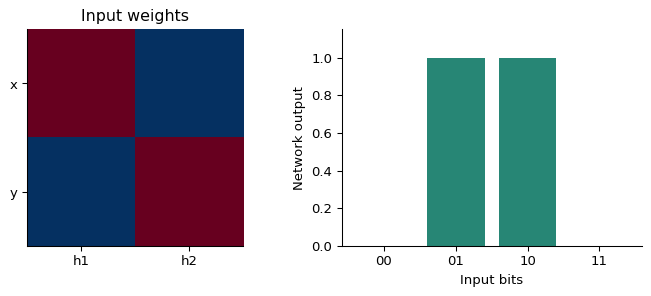

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
W = np.array([[1.0, -1.0], [-1.0, 1.0]])
v = np.ones(2)
hidden = np.maximum(0, X @ W)
out = hidden @ v
truth = np.logical_xor(X[:, 0], X[:, 1]).astype(int)
assert np.array_equal(truth, out)
print("x y | h1 h2 | XOR")
print(np.column_stack((X, hidden, out)).astype(int))
fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
a.imshow(W, cmap="RdBu_r", vmin=-1, vmax=1)
a.set(
    xticks=[0, 1],
    xticklabels=["h1", "h2"],
    yticks=[0, 1],
    yticklabels=["x", "y"],
    title="Input weights",
)
b.bar(["00", "01", "10", "11"], out, color="#278675")
b.set(ylim=(0, 1.15), xlabel="Input bits", ylabel="Network output")
plt.show()

## Interpreting the result

All four inputs can be tested exhaustively. Away from those four points the same network computes an absolute difference.

## Exercise

Construct AND with one rectifier and test it on the same truth table.

## References

[McCulloch and Pitts, threshold logic (1943)](https://doi.org/10.1007/BF02478259)

[WeightCode, weight-space programming preprint (2026)](https://arxiv.org/abs/2611.25476)